<a href="https://colab.research.google.com/github/em2tech/Machine_Learning_SJU/blob/main/HW4/HW4%20-%20Analysis%20Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**HW4 - Analysis Report - Heart Disease Classification (UCI Cleveland)**

**1. How do the feature types in the UCI Heart Disease dataset (combining continuous physiological telemetry like chol and thalach with categorical/ordinal indicators like cp and thal) differ from previous datasets, and why is proper scaling critical for Support Vector Machines compared to Decision Trees?**




**Ans: How this dataset differs.** Unlike many introductory
datasets, which contain one kind of feature (all pixels, all sensor readings, or all survey categories), the Cleveland data is mixed-type:

**•	Continuous vitals on very different scales:** chol spans 126–564, while oldpeak spans only 0–6.2. Some, like chol and oldpeak, are skewed.

**•	Nominal categories stored as numbers:** in cp, thal and restecg, the codes are labels, not quantities. Treating them as numbers would impose a false order.

**•	Ordinal and binary indicators:** ca and slope are ordinal; sex, fbs and exang are binary flags.
Because of this mix, we used a ColumnTransformer that standardizes the continuous features and one-hot encodes the categorical ones.

**Why scaling matters for the SVC.** The RBF kernel relies on Euclidean distance between patients. Without scaling, large-unit features dominate: a 50 mg/dl cholesterol difference outweighs a clinically major 2 mm ST depression difference by over 600 times. Standardization gives every feature a comparable influence and makes the default gamma="scale" meaningful.

**Why Decision Trees don't need it.** A tree splits on one feature at a time using thresholds. Rescaling a feature keeps the patients in the same order, so the splits are unchanged and only the threshold values move. Trees never combine features into a distance, so units don't compete. One-hot encoding still matters for trees, though, because it prevents false orderings among categories such as chest-pain types.


**2. Explain how hidden missing values (such as ? symbols) impact raw medical datasets, and justify your choice of imputation strategies for skewed numerical vitals versus categorical diagnostic fields.**

**Answer:**
Although isnull() reported no missing values, 6 cells contained?: 4 in ca and 2 in thal, affecting about 2% of patients. The only clues were that info() listed these columns as text and value_counts() showed a stray ? category.

Why hidden placeholders are harmful:

1.	They pass standard null checks, so the gap can go unnoticed.
2.	They turn numeric columns into text, which breaks summary statistics and calculations.
3.	They can become fake categories after encoding, letting the model learn from "not recorded" as if it were a clinical finding.
4.	They break models, or worse, get coerced to 0. For ca, 0 is a real value ("no blocked vessels").

We converted ? to NaN, cast the columns back to numeric, and then imputed.
Imputation strategy:

**•	Numerical vitals → median.** Features like chol and oldpeak are right-skewed with outliers. The median reflects a typical patient, while the mean would be pulled toward extreme values.

**•	Categorical fields → mode.** Averaging category codes produces values that don't exist; the mean thal code is about 4.7, for example. The mode always gives a valid category (ca = 0, thal = 3). With only 2% of rows affected, this barely changes the distributions and keeps every patient.

**Avoiding leakage.** The imputers sit inside the pipeline, so they learn only from the training data. One limitation is that mode imputation leans slightly toward "healthy" categories. With more missing data, a missing-value indicator or KNNImputer/IterativeImputer would be better choices.


**3. Contrast how a Support Vector Classifier (using an RBF kernel) constructs decision boundaries versus how a Decision Tree recursively partitions feature space. What are the interpretability tradeoffs between the two models?**

**Answer:**

How the RBF SVC builds its boundary. The SVC finds the boundary with the widest possible margin between classes. The RBF kernel lets it draw a smooth, curved boundary that considers all features at once, defined by the borderline patients nearest it (the support vectors). This captures gradual, combined effects, such as a somewhat low maximum heart rate together with moderate ST depression.

How the Decision Tree partitions space. The tree repeatedly splits on one feature at a time, choosing the threshold that best separates the classes. This carves the data into rectangular regions with step-shaped boundaries. Our pruned tree split first on thal, then on cp or ca, followed by oldpeak, age, and thalach.

**Results.**

**•	Unconstrained tree:** it memorized the training data (100% train accuracy) but reached only 75.4% test accuracy and 0.762 AUC.

**•	Default SVC:** it generalized much better, with 88.5% test accuracy and 0.963 AUC, because margin maximization acts as built-in regularization.

**•	Pruned tree:** it still trailed the SVC (CV AUC 0.855 vs. 0.88–0.91), since smooth boundaries suit data where risk rises gradually across several vitals.


**Interpretability Trade-offs**

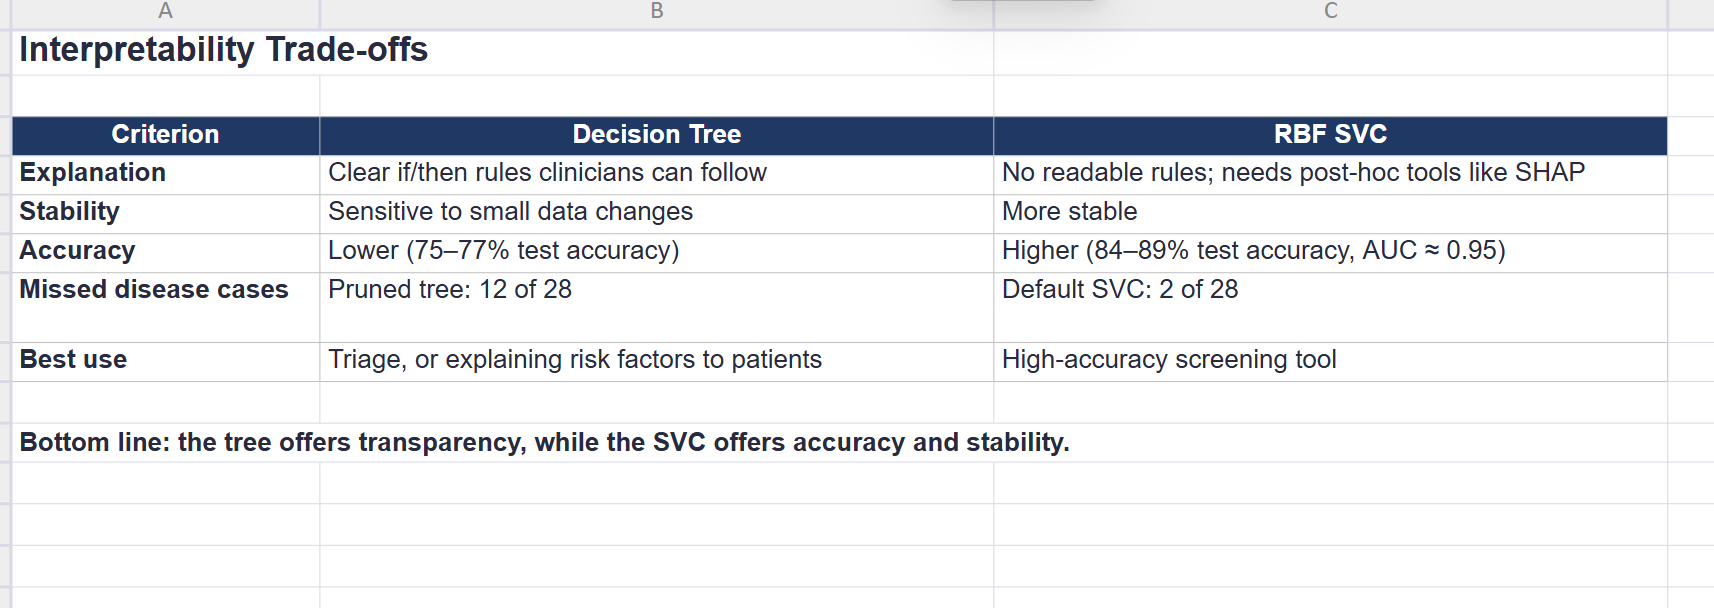

**Model Performance (UCI Cleveland, 61-patient test set)**

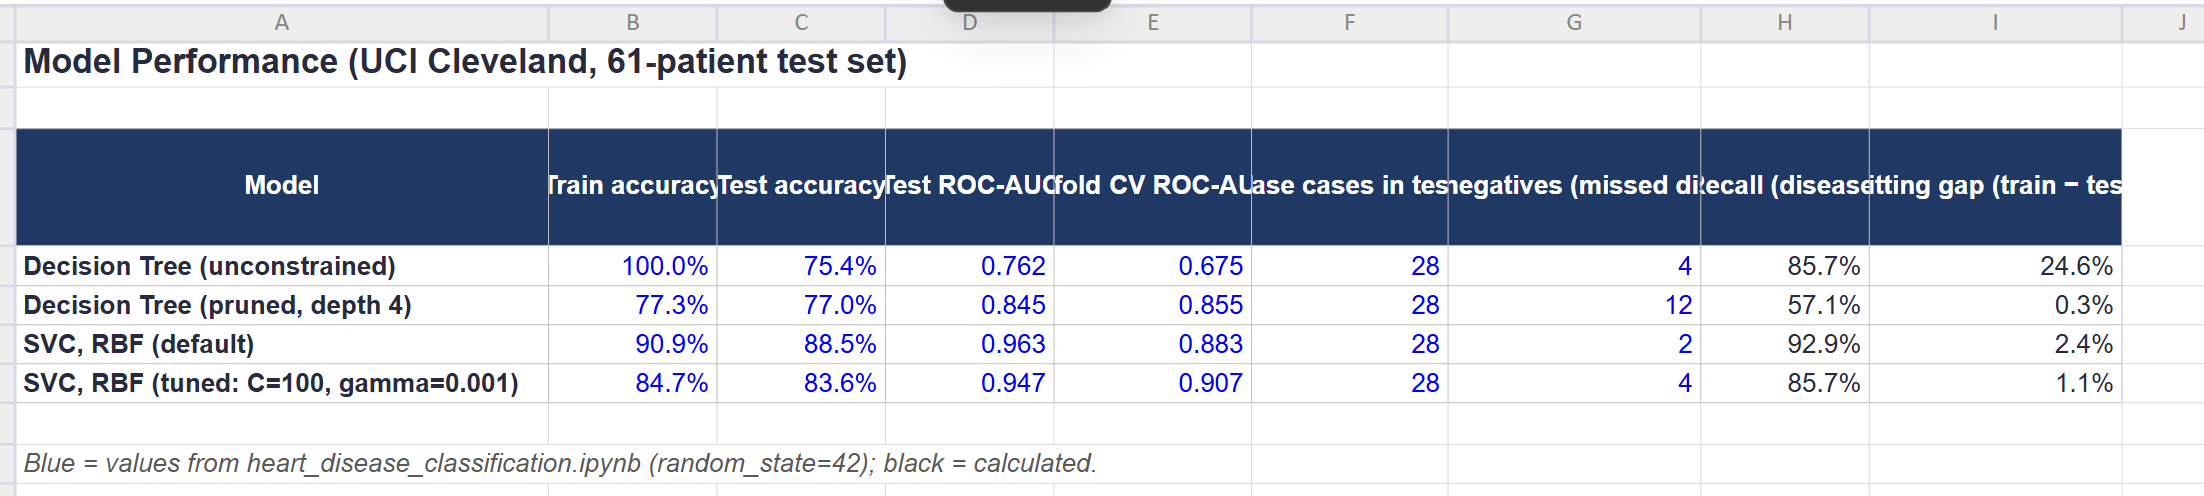

**SVC (RBF) vs. Decision Tree: How Each Model Separates Patients**

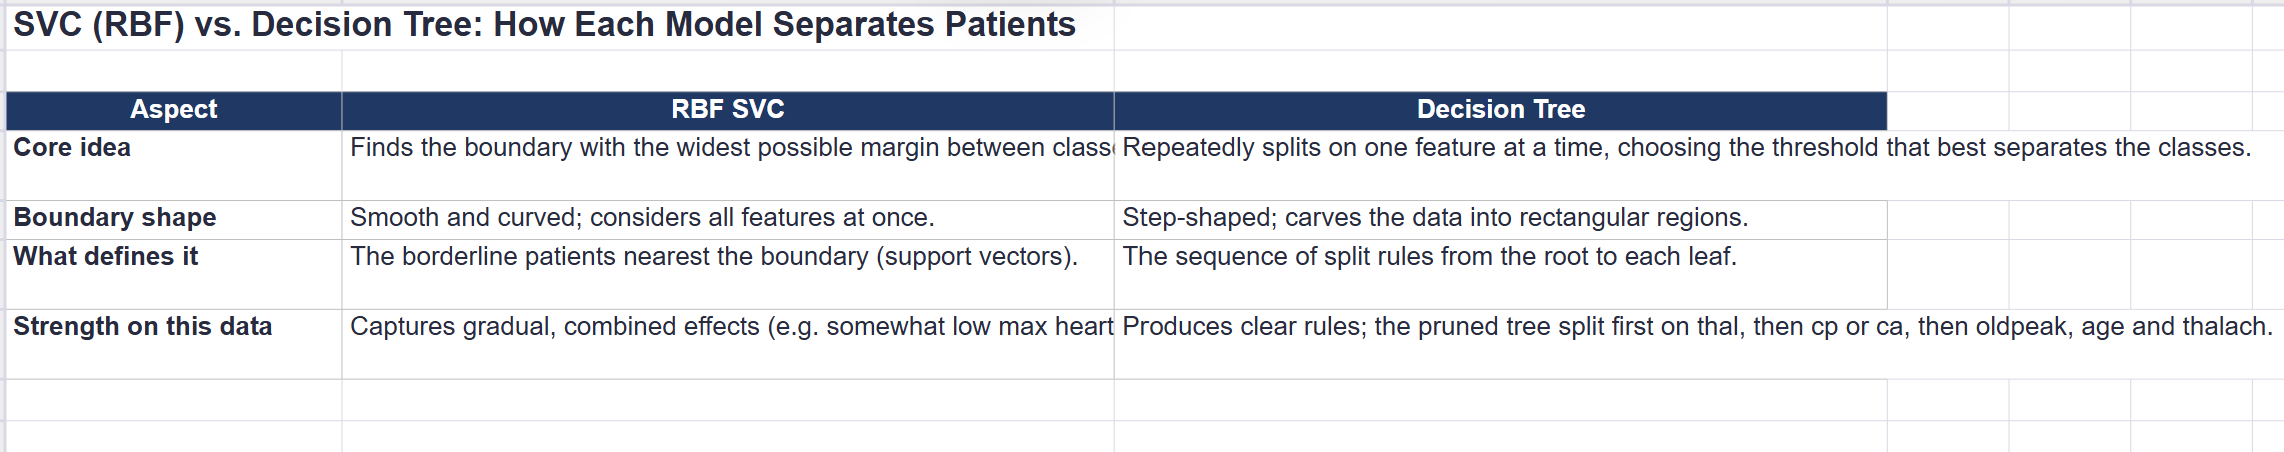

In [4]:
from IPython.display import Image, Markdown, display

images = [
    ("Interpretability Trade-offs", "/content/Interpretability_Trade_Offs.png"),
    ("Model Performance (UCI Cleveland, 61-patient test set)", "/content/Model_Performance.png"),
    ("SVC (RBF) vs. Decision Tree: How Each Model Separates Patients", "/content/SVC.png"),
]

for title, path in images:
    display(Markdown(f"**{title}**"))
    display(Image(filename=path, width=900))

**4. Discuss how tuning hyperparameters such as regularization parameter C and kernel coefficient gamma in an SVC impacts the trade-off between bias, variance, and model generalization on unseen medical test data.**

**Answer:**


C (regularization). C sets how heavily the SVC penalizes training mistakes.

**•	Small C:** a wide margin that tolerates errors, giving a simpler model with higher bias and lower variance.

**•	Large C:** the boundary bends to classify nearly every training patient correctly, giving lower bias but higher variance and a risk of fitting noise.
Gamma (kernel width). Gamma controls how far each patient's influence reaches.

**•	Small gamma:** broad influence and a smooth, almost linear boundary, giving higher bias and lower variance.

**•	Large gamma:** very local influence, so the boundary wraps around individual patients. Bias is low but variance is very high, and the model tends to memorize the training data.
Both parameters add flexibility, so the best results usually pair a large C with a small gamma, or the reverse.
Grid search results (5-fold CV ROC-AUC):

**•	Overfitting:** large C combined with large gamma did worst. C=100, gamma=0.1 dropped to 0.801 AUC with a large train–validation gap (0.199), and gamma=1 overfit at every C.

**•	Underfitting:** small C with small gamma plateaued around 0.879 AUC. The model was too smooth to capture all the signal.

**•	Best:** C=100, gamma=0.001 reached 0.907 AUC with a small gap (0.023). This suggests the data is close to linearly separable once it is properly scaled and encoded.

**Generalization.** Tuning raised CV AUC from 0.883 to 0.907 and narrowed the train–test gap, making the model more stable. On the 61-patient test set, the tuned model scored slightly lower (AUC 0.947 vs. 0.963). That gap is just two patients and falls within noise. Cross-validation is the more reliable guide, which is why hyperparameters should be chosen with CV and never by checking the test set. For real screening, the tuned model is the safer choice. Its decision threshold should also be adjusted to favor recall, because missing a diagnosis is far more costly than a false alarm.


**Answer:**

**Strongest predictors.** In both the decision tree and the SVC, thal, ca, cp and oldpeak were the dominant predictors, with thalach and exang playing a supporting role. The full tree also gave weight to chol and age, but that came from overfitting: after pruning, chol dropped to nearly zero, and the SVC ignored it too.

**What the raw data show:**

**•	thal:** the disease rate was 22% with a normal thallium scan vs. 76% with a reversible defect.

**•	ca:** risk rose steadily with the number of blocked vessels, from 26% (0) to 85% (3).

**•	cp:** asymptomatic patients had the highest disease rate (73%), compared with 18–30% for the other chest-pain types.

**•	oldpeak:** ST depression averaged 1.6 mm in diseased patients vs. 0.6 mm in healthy ones.

**•	thalach:** diseased patients reached a lower maximum heart rate (139 vs. 158 bpm).

**•	exang:** the disease rate was 77% with exercise-induced angina vs. 31% without.
Resting risk factors (cholesterol, blood pressure, blood sugar) added little here. Among patients already referred for cardiac evaluation, stress-test and imaging results separate diseased from healthy patients far better.

**Screening insights for cardiologists:**

**1.	Stress testing gives the most information**. Four of the top predictors come from it.

**2.	Don't dismiss asymptomatic patients.** No chest pain was the highest-risk category.

**3.	A simple triage rule emerged:** an abnormal thallium scan, plus no chest pain, plus ST depression above about 09 mm flagged 49 of 50 such training patients as diseased.

4.**Vessel count** helps confirm and stage the disease.

5.**A low peak** heart rate during exercise is an inexpensive warning sign.

6.**Use ML as decision support that favors recall.** The SVC caught 26 of 28 cases. Since this cohort is small, mostly male, and drawn from referred patients, the models need validation on broader populations.


**5. Inspecting your Decision Tree feature importances or model coefficients, which clinical indicators (e.g., maximum heart rate, chest pain type, ST depression) exhibit the strongest predictive power for heart disease, and what preventative screening insights do these results provide for cardiologists?**

**Answer:**

That's the same passage as your last message, so here's a shorter version in case the previous summary was too long:

**Key predictors.** In both models, the strongest predictors were the thallium stress test (thal), the number of blocked vessels (ca), chest pain type (cp) and ST depression (oldpeak). Maximum heart rate (thalach) and exercise-induced angina (exang) also contributed. Cholesterol, blood pressure and blood sugar added almost nothing in this group of referred patients.

**The data back this up:**

•	**An abnormal thallium **scan raised the disease rate from 22% to 76%.

•	**Risk climbed** from 26% with no blocked vessels to 85% with three.

•	**Asymptomatic patients** had the highest disease rate (73%).

•	**Diseased patients** showed more ST depression (1.6 vs. 0.6 mm) and a lower peak heart rate (139 vs. 158 bpm).

**Screening insights:** stress testing is the most informative screen, and patients without chest pain shouldn't be dismissed. A simple tree rule (abnormal thallium scan, no chest pain, ST depression above about 0.9 mm) identified 49 of 50 such patients as diseased. Vessel count helps stage disease, and a low peak heart rate during exercise is an inexpensive warning sign.

**Caution:** ML works best as decision support that prioritizes catching disease; the SVC detected 26 of 28 cases. Because the dataset is small, mostly male and drawn from referred patients, the models need validation on broader populations.
